In [38]:
import pandas as pd
import seaborn as sb
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler



## 1. Charger le dataset


In [39]:
transactions = pd.read_excel("../data/transactions.xlsx")
transactions.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Signification des colonnes

| Colonne | Signification |
|---|---|
| `InvoiceNo` | Numéro de facture / transaction |
| `StockCode` | Identifiant du produit |
| `Description` | Description du produit |
| `Quantity` | Quantité achetée |
| `InvoiceDate` | Date de la transaction |
| `UnitPrice` | Prix unitaire |
| `CustomerID` | Identifiant du client |
| `Country` | Pays du client |


## 2. Première exploration


In [40]:
transactions.shape

(541909, 8)

In [41]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [42]:
transactions.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


In [43]:
transactions.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

## 3. Valeurs manquantes

In [44]:
missing = pd.DataFrame({
    "Nombre": transactions.isna().sum(),
    "Pourcentage": transactions.isna().mean() * 100
})

missing.sort_values("Pourcentage", ascending=False)


,Nombre,Pourcentage
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


In [45]:
transactions = transactions.dropna(subset=["CustomerID"])


## 4. Vérifier les quantités

In [46]:
transactions["Quantity"].describe()

count    406829.000000
mean         12.061303
std         248.693370
min      -80995.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [47]:
(transactions["Quantity"] <= 0).sum()

np.int64(8905)

## 5. Définir les transactions valides

In [48]:
transactions_clean = transactions[
    (transactions["Quantity"] > 0) &
    (transactions["UnitPrice"] > 0) &
    (~transactions["InvoiceNo"].astype(str).str.startswith("C"))
].copy()


#### A. Distribution du montant

#### B. Distribution des quantités

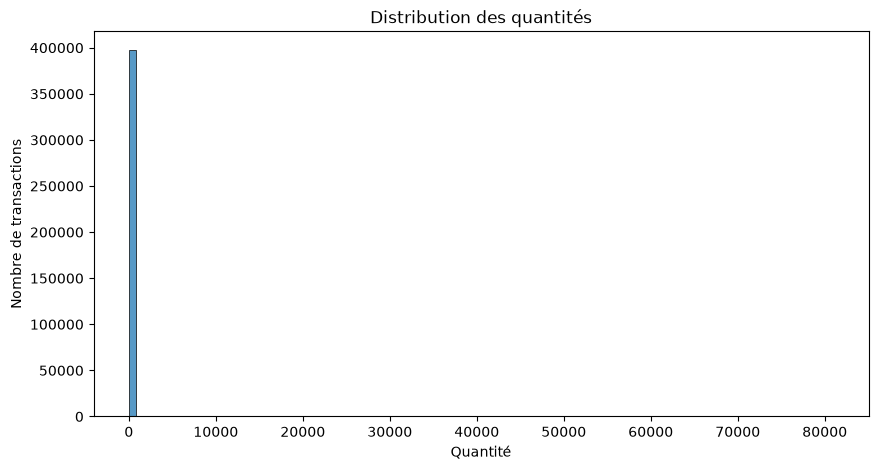

In [49]:
plt.figure(figsize=(10, 5))

sb.histplot(
    transactions_clean["Quantity"],
    bins=100
)

plt.title("Distribution des quantités")
plt.xlabel("Quantité")
plt.ylabel("Nombre de transactions")

plt.show()


### 6. Calcul RFM

In [50]:
refDate = transactions_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = transactions_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate",lambda dates: (refDate - dates.max()).days),
    Frequency=("InvoiceNo","nunique")
).join(
    transactions_clean.groupby("CustomerID").apply(
        lambda t: (t["UnitPrice"] * t["Quantity"]).sum()
    ).rename("Monetary")
)
rfm

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
...,...,...,...
18280.0,278,1,180.60
18281.0,181,1,80.82
18282.0,8,2,178.05


### 7. Visualisation des distributions RFM

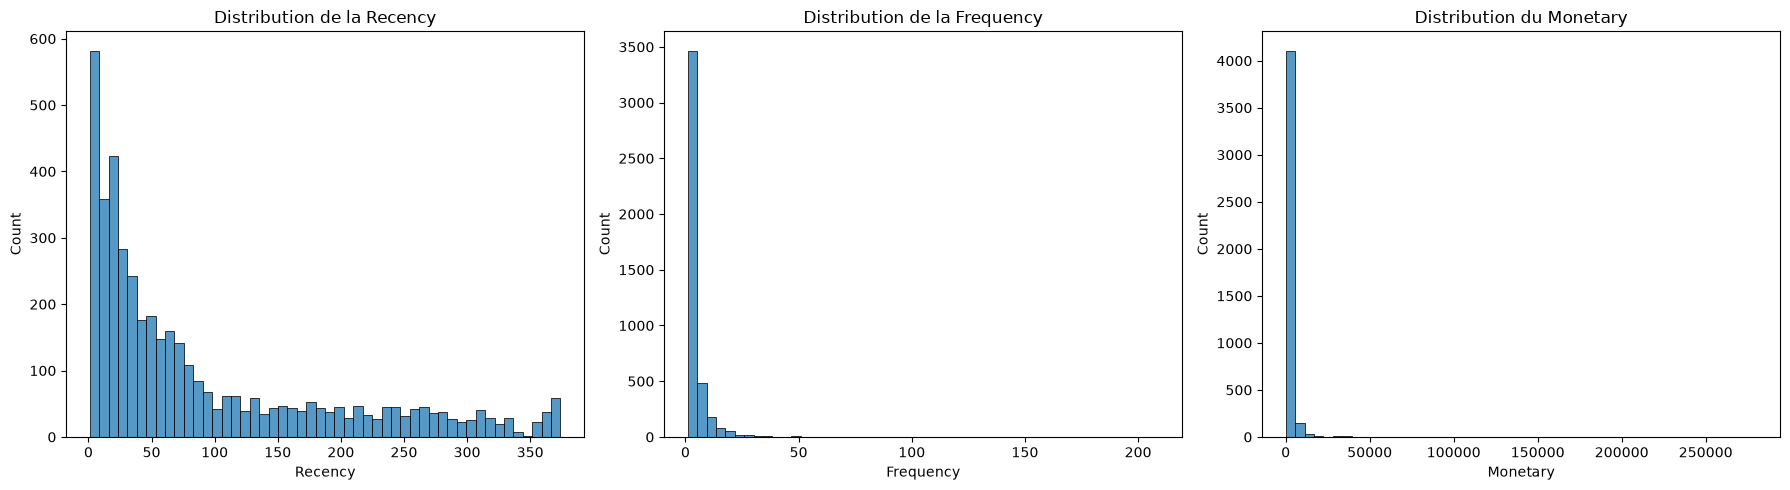

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sb.histplot(rfm["Recency"], bins=50, ax=axes[0])
axes[0].set_title("Distribution de la Recency")

sb.histplot(rfm["Frequency"], bins=50, ax=axes[1])
axes[1].set_title("Distribution de la Frequency")

sb.histplot(rfm["Monetary"], bins=50, ax=axes[2])
axes[2].set_title("Distribution du Monetary")

plt.tight_layout()
plt.show()

In [52]:
rfm.to_csv("../data/rfm.csv", index=True)

In [53]:
rfm[["Recency", "Frequency", "Monetary"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.00,18.000,51.000,142.00,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.000,2.000,5.00,209.00
Monetary,4338.0,2054.266460,8989.230441,3.75,307.415,674.485,1661.74,280206.02


In [54]:
rfm[["Recency", "Frequency", "Monetary"]].skew()

Recency       1.246048
Frequency    12.067031
Monetary     19.324953
dtype: float64

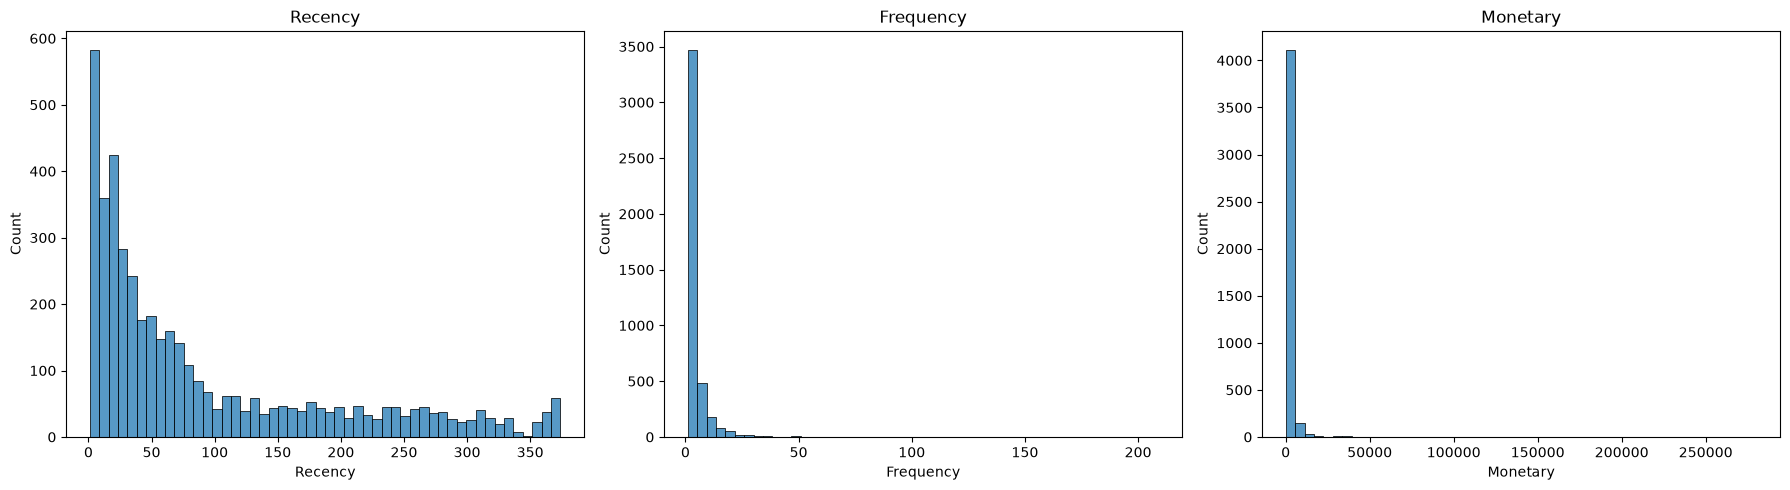

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sb.histplot(rfm["Recency"], bins=50, ax=axes[0])
axes[0].set_title("Recency")

sb.histplot(rfm["Frequency"], bins=50, ax=axes[1])
axes[1].set_title("Frequency")

sb.histplot(rfm["Monetary"], bins=50, ax=axes[2])
axes[2].set_title("Monetary")

plt.tight_layout()
plt.show()


In [56]:
rfm_log = rfm.copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

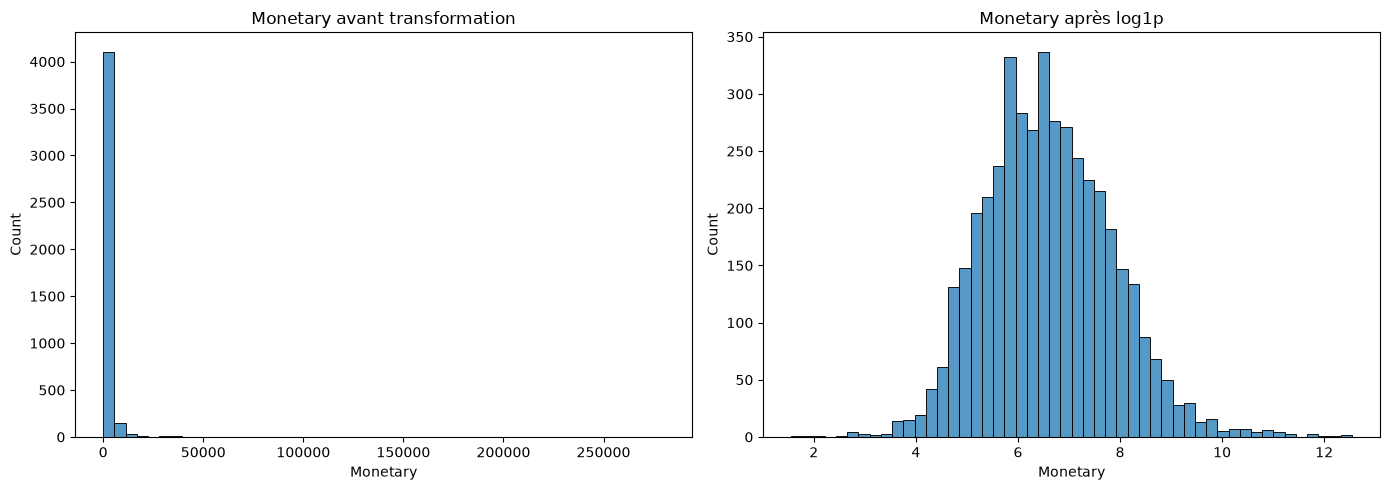

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sb.histplot(rfm["Monetary"], bins=50, ax=axes[0])
axes[0].set_title("Monetary avant transformation")

sb.histplot(rfm_log["Monetary"], bins=50, ax=axes[1])
axes[1].set_title("Monetary après log1p")

plt.tight_layout()
plt.show()
